In [420]:
'''import numpy as np


def sparse_nmf(
    V,
    n_components,
    *,
    W_init=None,
    H_init=None,
    lambda_sparse=0.1,
    g=None,
    g_prime=None,
    max_iter=500,
    tol=1e-5,
    eps=1e-10,
    random_state=None,
    return_history=False,
):
    """
    Sparse NMF using the multiplicative updates in equations (14) and (18).

    Parameters
    ----------
    V : array-like, shape (n_features, n_samples)
        Nonnegative input matrix. Each column is one sample.
    n_components : int
        Number of basis vectors.
    W_init : array-like, shape (n_features, n_components), optional
        Initial nonnegative basis matrix.
    H_init : array-like, shape (n_components, n_samples), optional
        Initial nonnegative activation matrix.
    lambda_sparse : float
        Sparsity regularization coefficient, lambda >= 0.
    g : callable, optional
        Elementwise sparsity penalty. Default: g(h) = h.
    g_prime : callable, optional
        Elementwise derivative of g. Default: g'(h) = 1.
        If a custom g is provided, g_prime must also be provided.
    max_iter : int
        Maximum number of iterations.
    tol : float
        Relative objective-change tolerance for stopping.
    eps : float
        Small positive constant for numerical stability.
    random_state : int, optional
        Random seed for initialization.
    return_history : bool
        If True, also return objective values and their components.

    Returns
    -------
    W : ndarray, shape (n_features, n_components)
        L2-normalized basis matrix.
    H : ndarray, shape (n_components, n_samples)
        Activation matrix.
    history : list of dicts, optional
        Returned only when return_history=True.

    Notes
    -----
    The returned matrices satisfy the reconstruction convention
        V_hat = W @ H
    with L2-normalized columns of W.
    """

    V = np.asarray(V, dtype=np.float64)

    if V.ndim != 2:
        raise ValueError("V must be a 2D matrix.")
    if not np.all(np.isfinite(V)) or np.any(V < 0):
        raise ValueError("V must contain finite, nonnegative values.")
    if not isinstance(n_components, (int, np.integer)) or n_components < 1:
        raise ValueError("n_components must be a positive integer.")
    if lambda_sparse < 0:
        raise ValueError("lambda_sparse must be nonnegative.")
    if max_iter < 1:
        raise ValueError("max_iter must be at least 1.")
    if tol < 0 or eps <= 0:
        raise ValueError("tol must be nonnegative and eps must be positive.")
    if (g is None) != (g_prime is None):
        raise ValueError("Provide both g and g_prime, or neither.")

    # Default: linear sparsity penalty, g(h) = h.
    if g is None:
        g = lambda h: h
        g_prime = lambda h: np.ones_like(h)

    n_features, n_samples = V.shape
    rng = np.random.default_rng(random_state)

    # Initialize W.
    if W_init is None:
        W = rng.random((n_features, n_components)) + eps
    else:
        W = np.asarray(W_init, dtype=np.float64).copy()
        if W.shape != (n_features, n_components):
            raise ValueError("W_init has an incorrect shape.")
        if not np.all(np.isfinite(W)) or np.any(W < 0):
            raise ValueError("W_init must be finite and nonnegative.")
        W = np.maximum(W, eps)

    # Initialize H.
    if H_init is None:
        H = rng.random((n_components, n_samples)) + eps
    else:
        H = np.asarray(H_init, dtype=np.float64).copy()
        if H.shape != (n_components, n_samples):
            raise ValueError("H_init has an incorrect shape.")
        if not np.all(np.isfinite(H)) or np.any(H < 0):
            raise ValueError("H_init must be finite and nonnegative.")
        H = np.maximum(H, eps)

    def elementwise(func, X, name):
        """Evaluate a penalty or derivative elementwise."""
        result = np.asarray(func(X), dtype=np.float64)

        try:
            result = np.broadcast_to(result, X.shape)
        except ValueError as exc:
            raise ValueError(
                f"{name} must return a scalar or an array "
                "broadcastable to the shape of H."
            ) from exc

        if not np.all(np.isfinite(result)):
            raise ValueError(f"{name} returned non-finite values.")

        return result

    def evaluate_objective(W_bar, H):
        """Objective: 0.5 * ||V - W_bar H||_F^2 + lambda * sum(g(H))."""
        R = W_bar @ H
        reconstruction_loss = 0.5 * np.sum((V - R) ** 2)

        penalty = elementwise(g, H, "g")
        if np.any(penalty < 0):
            raise ValueError("g(H) must be nonnegative.")

        sparsity_loss = lambda_sparse * np.sum(penalty)
        return reconstruction_loss + sparsity_loss, reconstruction_loss, sparsity_loss

    history = []
    previous_loss = None

    for iteration in range(1, max_iter + 1):

        # ---------------------------------------------------------
        # Steps 1-3:
        # Compute the gradient of each basis norm, normalize W,
        # and reconstruct V.
        # ---------------------------------------------------------
        norms = np.linalg.norm(W, axis=0)
        W_bar = W / np.maximum(norms, eps)[None, :]

        # For the L2 norm: grad_W ||W_j||_2 = W_j / ||W_j||_2.
        grad_norm = W_bar

        R = W_bar @ H

        # ---------------------------------------------------------
        # Step 4: update H using equation (14).
        #
        # H[j, i] <- H[j, i] *
        #   (W_bar[:, j]^T V[:, i]) /
        #   (W_bar[:, j]^T R[:, i] + lambda * g'(H[j, i]))
        # ---------------------------------------------------------
        sparse_gradient = elementwise(g_prime, H, "g_prime")
        if np.any(sparse_gradient < 0):
            raise ValueError(
                "g_prime(H) must be nonnegative for this multiplicative update."
            )

        H_num = W_bar.T @ V
        H_den = W_bar.T @ R + lambda_sparse * sparse_gradient

        H *= H_num / np.maximum(H_den, eps)
        H = np.maximum(H, eps)

        # ---------------------------------------------------------
        # Step 5: reconstruct using the updated activations.
        # ---------------------------------------------------------
        R = W_bar @ H

        # ---------------------------------------------------------
        # Step 6: update the non-normalized W using equation (18).
        #
        # W_j <- W_j * numerator_j / denominator_j
        #
        # All components are updated simultaneously.
        # ---------------------------------------------------------
        proj_R = W_bar.T @ R
        proj_V = W_bar.T @ V

        # Scalar sums over samples i, one value per component j.
        weighted_R_proj = np.sum(H * proj_R, axis=1)[None, :]
        weighted_V_proj = np.sum(H * proj_V, axis=1)[None, :]

        W_num = V @ H.T + grad_norm * weighted_R_proj
        W_den = R @ H.T + grad_norm * weighted_V_proj

        W *= np.maximum(W_num, 0.0) / np.maximum(W_den, eps)
        W = np.maximum(W, eps)

        # ---------------------------------------------------------
        # Evaluate convergence using the updated basis directions.
        # ---------------------------------------------------------
        norms = np.linalg.norm(W, axis=0)
        W_bar = W / np.maximum(norms, eps)[None, :]

        loss, rec_loss, sparse_loss = evaluate_objective(W_bar, H)

        if previous_loss is None:
            relative_change = None
        else:
            relative_change = (
                abs(previous_loss - loss) / max(abs(previous_loss), eps)
            )

        history.append({
            "iteration": iteration,
            "loss": loss,
            "reconstruction_loss": rec_loss,
            "sparsity_penalty": sparse_loss,
            "relative_change": relative_change,
        })

        if previous_loss is not None and relative_change < tol:
            break

        previous_loss = loss

    # Return normalized bases, consistent with the reconstruction in step 3.
    W_final = W / np.maximum(np.linalg.norm(W, axis=0), eps)[None, :]

    if return_history:
        return W_final, H, history

    return W_final, H'''

'''def sparse_nmf(
    V,
    n_components,
    *,
    W_init=None,
    H_init=None,
    lambda_sparse=0.1,
    lambda_vol=2.0,
    g=None,
    g_prime=None,
    max_iter=500,
    tol=1e-5,
    eps=1e-10,
    random_state=None,
    return_history=False,
):
    """
    Sparse NMF with signed volume regularization.

    Objective
    ---------
        min_{W,H >= 0}
            0.5 * ||V - W_bar @ H||_F^2
            + lambda_sparse * sum(g(H))
            + 0.5 * lambda_vol
                * logdet(W_bar.T @ W_bar + eps * I)

    where W_bar contains L2-normalized columns of W.

    Parameters
    ----------
    V : array-like, shape (n_features, n_samples)
        Nonnegative input matrix.

    n_components : int
        Number of basis vectors.

    W_init : array-like, optional
        Initial basis matrix, shape (n_features, n_components).

    H_init : array-like, optional
        Initial activation matrix, shape (n_components, n_samples).

    lambda_sparse : float
        Nonnegative sparsity regularization coefficient.

    lambda_vol : float
        Signed volume regularization coefficient:
            > 0 : minimum-volume regularization
            = 0 : original sparse NMF algorithm
            < 0 : maximum-volume regularization

    g : callable, optional
        Elementwise sparsity penalty. Default: g(h) = h.

    g_prime : callable, optional
        Elementwise derivative of g. Default: g'(h) = 1.
        If g is supplied, g_prime must also be supplied.

    max_iter : int
        Maximum number of iterations.

    tol : float
        Relative objective-change tolerance.

    eps : float
        Numerical-stability constant. Also regularizes the
        Gram matrix in the volume term when lambda_vol != 0.

    random_state : int, optional
        Random seed.

    return_history : bool
        If True, return the objective history.

    Returns
    -------
    W_final : ndarray, shape (n_features, n_components)
        L2-normalized basis matrix.

    H : ndarray, shape (n_components, n_samples)
        Activation matrix.

    history : list of dicts, optional
        Returned only when return_history=True.

    Notes
    -----
    When lambda_vol == 0, the original multiplicative updates,
    objective, and convergence calculation are retained.

    For nonzero lambda_vol, the W update incorporates the
    projected gradient of the signed log-determinant regularizer
    and uses backtracking to accept only non-increasing
    objective steps.
    """

    V = np.asarray(V, dtype=np.float64)

    if V.ndim != 2:
        raise ValueError("V must be a 2D matrix.")

    if not np.all(np.isfinite(V)) or np.any(V < 0):
        raise ValueError("V must contain finite, nonnegative values.")

    if not isinstance(n_components, (int, np.integer)) \
            or n_components < 1:
        raise ValueError("n_components must be a positive integer.")

    if lambda_sparse < 0 or not np.isfinite(lambda_sparse):
        raise ValueError("lambda_sparse must be finite and nonnegative.")

    if not np.isfinite(lambda_vol):
        raise ValueError("lambda_vol must be finite.")

    if max_iter < 1:
        raise ValueError("max_iter must be at least 1.")

    if tol < 0 or eps <= 0:
        raise ValueError("tol must be nonnegative and eps must be positive.")

    if (g is None) != (g_prime is None):
        raise ValueError("Provide both g and g_prime, or neither.")

    # Default sparsity penalty.
    if g is None:
        g = lambda h: h
        g_prime = lambda h: np.ones_like(h)

    n_features, n_samples = V.shape
    rng = np.random.default_rng(random_state)

    # ---------------------------------------------------------
    # Initialize W.
    # ---------------------------------------------------------
    if W_init is None:
        W = rng.random((n_features, n_components)) + eps
    else:
        W = np.asarray(W_init, dtype=np.float64).copy()

        if W.shape != (n_features, n_components):
            raise ValueError("W_init has an incorrect shape.")

        if not np.all(np.isfinite(W)) or np.any(W < 0):
            raise ValueError("W_init must be finite and nonnegative.")

        W = np.maximum(W, eps)

    # ---------------------------------------------------------
    # Initialize H.
    # ---------------------------------------------------------
    if H_init is None:
        H = rng.random((n_components, n_samples)) + eps
    else:
        H = np.asarray(H_init, dtype=np.float64).copy()

        if H.shape != (n_components, n_samples):
            raise ValueError("H_init has an incorrect shape.")

        if not np.all(np.isfinite(H)) or np.any(H < 0):
            raise ValueError("H_init must be finite and nonnegative.")

        H = np.maximum(H, eps)

    def elementwise(func, X, name):
        result = np.asarray(func(X), dtype=np.float64)

        try:
            result = np.broadcast_to(result, X.shape)
        except ValueError as exc:
            raise ValueError(
                f"{name} must return a scalar or an array "
                "broadcastable to the shape of H."
            ) from exc

        if not np.all(np.isfinite(result)):
            raise ValueError(f"{name} returned non-finite values.")

        return result

    def volume_value_and_gradient(W_bar):
        """
        R_vol = 0.5 * logdet(W_bar.T @ W_bar + eps * I).

        Gradient with respect to W_bar:
            W_bar @ inv(W_bar.T @ W_bar + eps * I)
        """
        gram = W_bar.T @ W_bar
        gram.flat[::n_components + 1] += eps

        sign, logdet = np.linalg.slogdet(gram)

        if sign <= 0 or not np.isfinite(logdet):
            raise FloatingPointError(
                "Invalid log-determinant of the regularized Gram matrix."
            )

        volume = 0.5 * logdet

        # Avoid explicitly calculating the matrix inverse.
        inv_gram = np.linalg.solve(
            gram,
            np.eye(n_components),
        )

        gradient = W_bar @ inv_gram

        # Project onto the tangent space of the unit-L2 spheres.
        # Radial changes disappear when W is normalized.
        radial = np.sum(
            W_bar * gradient,
            axis=0,
            keepdims=True,
        )

        gradient -= W_bar * radial

        return volume, gradient

    def evaluate_objective(W_bar, H):
        R = W_bar @ H

        reconstruction_loss = 0.5 * np.sum((V - R) ** 2)

        penalty = elementwise(g, H, "g")

        if np.any(penalty < 0):
            raise ValueError("g(H) must be nonnegative.")

        sparsity_loss = lambda_sparse * np.sum(penalty)

        # Preserve the original objective exactly when lambda_vol == 0.
        if lambda_vol == 0.0:
            return (
                reconstruction_loss + sparsity_loss,
                reconstruction_loss,
                sparsity_loss,
                0.0,
            )

        volume, _ = volume_value_and_gradient(W_bar)
        volume_penalty = lambda_vol * volume

        loss = (
            reconstruction_loss
            + sparsity_loss
            + volume_penalty
        )

        return loss, reconstruction_loss, sparsity_loss, volume

    history = []
    previous_loss = None

    for iteration in range(1, max_iter + 1):

        # ---------------------------------------------------------
        # 1. Normalize W and reconstruct.
        # ---------------------------------------------------------
        norms = np.linalg.norm(W, axis=0)
        W_bar = W / np.maximum(norms, eps)[None, :]

        grad_norm = W_bar

        R = W_bar @ H

        # ---------------------------------------------------------
        # 2. Update H using the original sparse multiplicative rule.
        # ---------------------------------------------------------
        sparse_gradient = elementwise(g_prime, H, "g_prime")

        if np.any(sparse_gradient < 0):
            raise ValueError(
                "g_prime(H) must be nonnegative for this "
                "multiplicative update."
            )

        H_num = W_bar.T @ V
        H_den = W_bar.T @ R + lambda_sparse * sparse_gradient

        H *= H_num / np.maximum(H_den, eps)
        H = np.maximum(H, eps)

        # ---------------------------------------------------------
        # 3. Reconstruct using updated H.
        # ---------------------------------------------------------
        R = W_bar @ H

        # ---------------------------------------------------------
        # 4. Construct the original W multiplicative update.
        # ---------------------------------------------------------
        proj_R = W_bar.T @ R
        proj_V = W_bar.T @ V

        weighted_R_proj = np.sum(
            H * proj_R, axis=1
        )[None, :]

        weighted_V_proj = np.sum(
            H * proj_V, axis=1
        )[None, :]

        W_num = (
            V @ H.T
            + grad_norm * weighted_R_proj
        )

        W_den = (
            R @ H.T
            + grad_norm * weighted_V_proj
        )

        # ---------------------------------------------------------
        # 5. Original algorithm: retain exactly the original W step.
        # ---------------------------------------------------------
        if lambda_vol == 0.0:

            W *= (
                np.maximum(W_num, 0.0)
                / np.maximum(W_den, eps)
            )

            W = np.maximum(W, eps)

        else:
            # -----------------------------------------------------
            # Signed volume gradient.
            #
            # For positive lambda_vol, minimize log-volume.
            # For negative lambda_vol, maximize log-volume.
            # -----------------------------------------------------
            _, grad_volume = volume_value_and_gradient(W_bar)

            signed_gradient = lambda_vol * grad_volume

            # Existing multiplicative updates represent the gradient
            # as denominator - numerator.
            #
            # Add positive gradient entries to the denominator,
            # and negative gradient entries to the numerator.
            W_num_vol = np.maximum(-signed_gradient, 0.0)
            W_den_vol = np.maximum(signed_gradient, 0.0)

            W_num_total = (
                np.maximum(W_num, 0.0) + W_num_vol
            )

            W_den_total = (
                np.maximum(W_den, eps) + W_den_vol
            )

            W_candidate = W * (
                W_num_total / W_den_total
            )

            W_candidate = np.maximum(W_candidate, eps)

            # -----------------------------------------------------
            # Backtracking: accept only if the complete objective
            # does not increase, with H held fixed.
            # -----------------------------------------------------
            old_W = W.copy()

            base_loss, *_ = evaluate_objective(W_bar, H)

            alpha = 1.0
            accepted = False

            for _ in range(30):

                W_trial = old_W + alpha * (
                    W_candidate - old_W
                )

                W_trial = np.maximum(W_trial, eps)

                trial_norms = np.linalg.norm(W_trial, axis=0)

                W_trial_bar = W_trial / np.maximum(
                    trial_norms, eps
                )[None, :]

                trial_loss, *_ = evaluate_objective(
                    W_trial_bar, H
                )

                tolerance = 1e-12 * max(1.0, abs(base_loss))

                if (
                    np.isfinite(trial_loss)
                    and trial_loss <= base_loss + tolerance
                ):
                    W = W_trial
                    accepted = True
                    break

                alpha *= 0.5

            if not accepted:
                # Keep the previous basis if no candidate step succeeds.
                W = old_W

        # ---------------------------------------------------------
        # 6. Evaluate convergence using normalized basis directions.
        # ---------------------------------------------------------
        norms = np.linalg.norm(W, axis=0)
        W_bar = W / np.maximum(norms, eps)[None, :]

        (
            loss,
            rec_loss,
            sparse_loss,
            volume,
        ) = evaluate_objective(W_bar, H)

        if previous_loss is None:
            relative_change = None
        else:
            relative_change = (
                abs(previous_loss - loss)
                / max(abs(previous_loss), eps)
            )

        entry = {
            "iteration": iteration,
            "loss": loss,
            "reconstruction_loss": rec_loss,
            "sparsity_penalty": sparse_loss,
            "relative_change": relative_change,
        }

        # Keep the original history schema when lambda_vol == 0.
        if lambda_vol != 0.0:
            entry["log_volume"] = volume
            entry["volume_penalty"] = lambda_vol * volume

        history.append(entry)

        if previous_loss is not None and relative_change < tol:
            break

        previous_loss = loss

    W_final = W / np.maximum(
        np.linalg.norm(W, axis=0), eps
    )[None, :]

    if return_history:
        return W_final, H, history

    return W_final, H'''
import numpy as np
np.random.seed(42)
def sparse_nmf(
    V,
    n_components,
    *,
    W_init=None,
    H_init=None,
    lambda_sparse=0.1,
    lambda_vol=2.0,
    lambda_span=0.0,
    span_indices=None,
    g=None,
    g_prime=None,
    max_iter=500,
    tol=1e-5,
    eps=1e-10,
    random_state=None,
    return_history=False,
):
    """
    Sparse NMF with optional signed volume regularization
    and linear-subspace regularization.

    Objective
    ---------
        min_{W,H >= 0}

            0.5 * ||V - W_bar @ H||_F^2
            + lambda_sparse * sum(g(H))
            + 0.5 * lambda_vol
                * logdet(W_bar.T @ W_bar + eps * I)
            + lambda_span * R_span(W_bar)

    where W_bar has unit-L2-norm columns and

        R_span(W_bar) =
            sum_j ||(I - Q @ Q.T) @ W_bar[:, j]||_2

    Q is an orthonormal basis for the column space of
    V[:, span_indices].

    Parameters
    ----------
    V : array-like, shape (n_features, n_samples)
        Nonnegative data matrix.

    n_components : int
        Number of basis vectors.

    W_init : array-like, optional
        Initial basis matrix, shape (n_features, n_components).

    H_init : array-like, optional
        Initial activation matrix, shape (n_components, n_samples).

    lambda_sparse : float
        Nonnegative sparsity coefficient.

    lambda_vol : float
        Signed volume coefficient:
            positive -> minimum volume
            zero     -> no volume regularization
            negative -> maximum volume

    lambda_span : float
        Nonnegative coefficient for the linear-subspace penalty.

    span_indices : array-like of int, optional
        Indices of data columns used to construct the subspace.
        Required when lambda_span > 0.

        The selected columns should span a proper subspace of
        R**n_features. For example, use reliable mono­phonic frames.

    g, g_prime : callable, optional
        Elementwise sparsity penalty and its derivative.
        Both must be supplied together.

    max_iter : int
        Maximum number of iterations.

    tol : float
        Relative objective-change stopping tolerance.

    eps : float
        Numerical stability constant.

    random_state : int, optional
        Random seed.

    return_history : bool
        Whether to return the objective history.

    Returns
    -------
    W_final, H : ndarray
        L2-normalized basis and activations.

    history : list of dict, optional
        Returned when return_history=True.
    """

    V = np.asarray(V, dtype=np.float64)

    if V.ndim != 2:
        raise ValueError("V must be a 2D matrix.")

    if not np.all(np.isfinite(V)) or np.any(V < 0):
        raise ValueError("V must contain finite, nonnegative values.")

    if not isinstance(n_components, (int, np.integer)) or n_components < 1:
        raise ValueError("n_components must be a positive integer.")

    if lambda_sparse < 0 or not np.isfinite(lambda_sparse):
        raise ValueError("lambda_sparse must be finite and nonnegative.")

    if not np.isfinite(lambda_vol):
        raise ValueError("lambda_vol must be finite.")

    if lambda_span < 0 or not np.isfinite(lambda_span):
        raise ValueError("lambda_span must be finite and nonnegative.")

    if max_iter < 1:
        raise ValueError("max_iter must be at least 1.")

    if tol < 0 or eps <= 0:
        raise ValueError("tol must be nonnegative and eps must be positive.")

    if (g is None) != (g_prime is None):
        raise ValueError("Provide both g and g_prime, or neither.")

    if g is None:
        g = lambda h: h
        g_prime = lambda h: np.ones_like(h)

    n_features, n_samples = V.shape

    if n_components > min(n_features, n_samples):
        raise ValueError(
            "n_components must not exceed min(n_features, n_samples)."
        )

    rng = np.random.default_rng(random_state)

    # ---------------------------------------------------------
    # Initialize W.
    # ---------------------------------------------------------
    if W_init is None:
        W = rng.random((n_features, n_components)) + eps
    else:
        W = np.asarray(W_init, dtype=np.float64).copy()

        if W.shape != (n_features, n_components):
            raise ValueError("W_init has an incorrect shape.")

        if not np.all(np.isfinite(W)) or np.any(W < 0):
            raise ValueError("W_init must be finite and nonnegative.")

        W = np.maximum(W, eps)

    # ---------------------------------------------------------
    # Initialize H.
    # ---------------------------------------------------------
    if H_init is None:
        H = rng.random((n_components, n_samples)) + eps
    else:
        H = np.asarray(H_init, dtype=np.float64).copy()

        if H.shape != (n_components, n_samples):
            raise ValueError("H_init has an incorrect shape.")

        if not np.all(np.isfinite(H)) or np.any(H < 0):
            raise ValueError("H_init must be finite and nonnegative.")

        H = np.maximum(H, eps)

    # ---------------------------------------------------------
    # Construct an orthonormal basis Q for the selected subspace.
    # Only done when the new regularizer is active.
    # ---------------------------------------------------------
    Q = None

    if lambda_span > 0.0:
        if span_indices is None:
            raise ValueError(
                "span_indices must be supplied when lambda_span > 0. "
                "Using all columns of V may make the penalty identically zero."
            )

        raw_indices = np.asarray(span_indices)

        if raw_indices.ndim != 1 or raw_indices.size == 0:
            raise ValueError("span_indices must be a nonempty 1D array.")

        if not np.issubdtype(raw_indices.dtype, np.integer):
            if (
                not np.all(np.isfinite(raw_indices))
                or not np.all(raw_indices == np.floor(raw_indices))
            ):
                raise ValueError("span_indices must contain integer indices.")

        indices = raw_indices.astype(np.int64)

        if np.any(indices < 0) or np.any(indices >= n_samples):
            raise ValueError("span_indices contain invalid column indices.")

        if np.unique(indices).size != indices.size:
            raise ValueError("span_indices must not contain duplicates.")

        A = V[:, indices].copy()

        # Column scaling does not change their linear span.
        # Normalize for more stable numerical rank estimation.
        col_norms = np.linalg.norm(A, axis=0)
        nonzero = col_norms > eps

        A = A[:, nonzero]
        col_norms = col_norms[nonzero]

        if A.shape[1] == 0:
            raise ValueError("Selected columns are all zero.")

        A /= col_norms[None, :]

        U, singular_values, _ = np.linalg.svd(
            A,
            full_matrices=False,
        )

        rank_tol = (
            max(A.shape)
            * np.finfo(np.float64).eps
            * singular_values[0]
        )

        numerical_rank = int(np.sum(singular_values > rank_tol))

        if numerical_rank == 0:
            raise ValueError("The selected columns have zero numerical rank.")

        if numerical_rank >= n_features:
            raise ValueError(
                "The selected columns span the entire feature space, "
                "so the linear-subspace regularizer would be identically zero. "
                "Select fewer or less diverse frames."
            )

        Q = U[:, :numerical_rank].copy()

    # ---------------------------------------------------------
    # Helper functions.
    # ---------------------------------------------------------
    def elementwise(func, X, name):
        result = np.asarray(func(X), dtype=np.float64)

        try:
            result = np.broadcast_to(result, X.shape)
        except ValueError as exc:
            raise ValueError(
                f"{name} must return a scalar or an array "
                "broadcastable to the shape of H."
            ) from exc

        if not np.all(np.isfinite(result)):
            raise ValueError(f"{name} returned non-finite values.")

        return result

    def volume_value_and_gradient(W_bar):
        gram = W_bar.T @ W_bar + eps * np.eye(n_components)

        sign, logdet = np.linalg.slogdet(gram)

        if sign <= 0 or not np.isfinite(logdet):
            raise FloatingPointError(
                "Invalid log-determinant of the regularized Gram matrix."
            )

        value = 0.5 * logdet

        inv_gram = np.linalg.solve(
            gram,
            np.eye(n_components),
        )

        gradient = W_bar @ inv_gram

        # Tangent projection for unit-L2-norm columns.
        radial = np.sum(
            W_bar * gradient,
            axis=0,
            keepdims=True,
        )

        gradient -= W_bar * radial

        return value, gradient

    def span_value_and_gradient(W_bar):
        """
        Smoothed sum of distances to the selected linear subspace.

        For each column w_j:
            r_j = (I - Q Q.T) w_j

        The penalty approximates sum_j ||r_j||_2.
        """
        residual = W_bar - Q @ (Q.T @ W_bar)

        residual_norms = np.sqrt(
            np.sum(residual**2, axis=0) + eps**2
        )

        value = np.sum(residual_norms - eps)

        gradient = residual / residual_norms[None, :]

        # Tangent projection for unit-L2-norm columns.
        radial = np.sum(
            W_bar * gradient,
            axis=0,
            keepdims=True,
        )

        gradient -= W_bar * radial

        return float(value), gradient

    def evaluate_objective(W_bar, H):
        R = W_bar @ H

        reconstruction_loss = 0.5 * np.sum((V - R) ** 2)

        penalty = elementwise(g, H, "g")

        if np.any(penalty < 0):
            raise ValueError("g(H) must be nonnegative.")

        sparsity_loss = lambda_sparse * np.sum(penalty)

        loss = reconstruction_loss + sparsity_loss

        volume = 0.0
        span_error = 0.0

        if lambda_vol != 0.0:
            volume, _ = volume_value_and_gradient(W_bar)
            loss += lambda_vol * volume

        if lambda_span > 0.0:
            span_error, _ = span_value_and_gradient(W_bar)
            loss += lambda_span * span_error

        return (
            loss,
            reconstruction_loss,
            sparsity_loss,
            volume,
            span_error,
        )

    # ---------------------------------------------------------
    # Main loop.
    # ---------------------------------------------------------
    history = []
    previous_loss = None

    for iteration in range(1, max_iter + 1):

        norms = np.linalg.norm(W, axis=0)
        W_bar = W / np.maximum(norms, eps)[None, :]

        grad_norm = W_bar
        R = W_bar @ H

        # -----------------------------------------------------
        # Update H using the original sparse multiplicative rule.
        # -----------------------------------------------------
        sparse_gradient = elementwise(g_prime, H, "g_prime")

        if np.any(sparse_gradient < 0):
            raise ValueError(
                "g_prime(H) must be nonnegative for this "
                "multiplicative update."
            )

        H_num = W_bar.T @ V
        H_den = W_bar.T @ R + lambda_sparse * sparse_gradient

        H *= H_num / np.maximum(H_den, eps)
        H = np.maximum(H, eps)

        R = W_bar @ H

        # -----------------------------------------------------
        # Original W multiplicative-update terms.
        # -----------------------------------------------------
        proj_R = W_bar.T @ R
        proj_V = W_bar.T @ V

        weighted_R_proj = np.sum(
            H * proj_R,
            axis=1,
        )[None, :]

        weighted_V_proj = np.sum(
            H * proj_V,
            axis=1,
        )[None, :]

        W_num = (
            V @ H.T
            + grad_norm * weighted_R_proj
        )

        W_den = (
            R @ H.T
            + grad_norm * weighted_V_proj
        )

        # -----------------------------------------------------
        # Exact original W step when both new terms are disabled.
        # -----------------------------------------------------
        if lambda_vol == 0.0 and lambda_span == 0.0:

            W *= (
                np.maximum(W_num, 0.0)
                / np.maximum(W_den, eps)
            )

            W = np.maximum(W, eps)

        else:
            # Sum the regularizer gradients.
            extra_gradient = np.zeros_like(W_bar)

            if lambda_vol != 0.0:
                _, grad_volume = volume_value_and_gradient(W_bar)
                extra_gradient += lambda_vol * grad_volume

            if lambda_span > 0.0:
                _, grad_span = span_value_and_gradient(W_bar)
                extra_gradient += lambda_span * grad_span

            # Positive gradient entries increase the denominator;
            # negative entries increase the numerator.
            W_num_total = (
                np.maximum(W_num, 0.0)
                + np.maximum(-extra_gradient, 0.0)
            )

            W_den_total = (
                np.maximum(W_den, eps)
                + np.maximum(extra_gradient, 0.0)
            )

            W_candidate = W * (
                W_num_total / W_den_total
            )

            W_candidate = np.maximum(W_candidate, eps)

            # Backtracking on the full objective, holding H fixed.
            old_W = W.copy()

            base_loss, *_ = evaluate_objective(W_bar, H)

            alpha = 1.0
            accepted = False

            for _ in range(30):
                W_trial = old_W + alpha * (W_candidate - old_W)
                W_trial = np.maximum(W_trial, eps)

                trial_norms = np.linalg.norm(W_trial, axis=0)
                W_trial_bar = W_trial / np.maximum(
                    trial_norms, eps
                )[None, :]

                trial_loss, *_ = evaluate_objective(W_trial_bar, H)

                allowed_increase = (
                    1e-12 * max(1.0, abs(base_loss))
                )

                if (
                    np.isfinite(trial_loss)
                    and trial_loss <= base_loss + allowed_increase
                ):
                    W = W_trial
                    accepted = True
                    break

                alpha *= 0.5

            if not accepted:
                W = old_W

        # -----------------------------------------------------
        # Evaluate objective and convergence.
        # -----------------------------------------------------
        norms = np.linalg.norm(W, axis=0)
        W_bar = W / np.maximum(norms, eps)[None, :]

        (
            loss,
            rec_loss,
            sparse_loss,
            volume,
            span_error,
        ) = evaluate_objective(W_bar, H)

        if previous_loss is None:
            relative_change = None
        else:
            relative_change = (
                abs(previous_loss - loss)
                / max(abs(previous_loss), eps)
            )

        entry = {
            "iteration": iteration,
            "loss": loss,
            "reconstruction_loss": rec_loss,
            "sparsity_penalty": sparse_loss,
            "relative_change": relative_change,
        }

        if lambda_vol != 0.0:
            entry["log_volume"] = volume
            entry["volume_penalty"] = lambda_vol * volume

        if lambda_span > 0.0:
            entry["span_error"] = span_error
            entry["span_penalty"] = lambda_span * span_error

        history.append(entry)

        if previous_loss is not None and relative_change < tol:
            break

        previous_loss = loss

    W_final = W / np.maximum(
        np.linalg.norm(W, axis=0), eps
    )[None, :]

    if return_history:
        return W_final, H, history

    return W_final, H

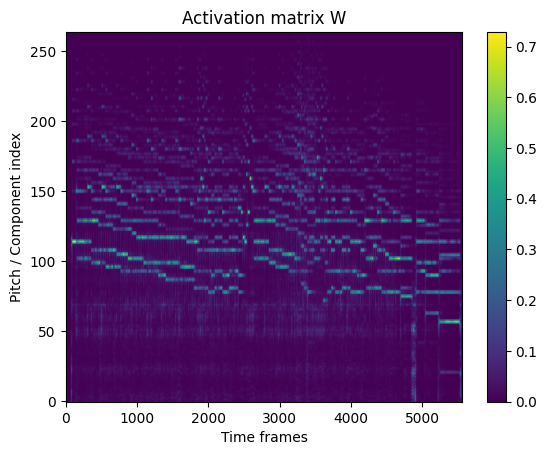

In [421]:
from scipy.io import wavfile
import librosa
import numpy as np
K = 3
HOP = 1024
file_name_string_audio = "Prelude-in-E-Minor-Nr-4.wav"
g = 2
f_s, x = wavfile.read(file_name_string_audio)
if(x.dtype==np.int32):
  x = x / (2**31)
elif(x.dtype==np.int16):
  x = x / (2**15)
else:
  raise ValueError(f"Unsupported sample type: {x.dtype}")
spectrogram = np.abs(librosa.cqt(x,sr=f_s, fmin=librosa.note_to_hz('A0'), bins_per_octave=12 * K, n_bins=88 * K, hop_length=HOP, sparsity=0.05))
#spectrogram_1 = np.abs(librosa.cqt(x,sr=f_s, fmin=librosa.note_to_hz('A0'), bins_per_octave=12 * K, n_bins=88 * K, hop_length=HOP))
onsets = librosa.onset.onset_detect(y=x, sr=f_s, hop_length=HOP,units='frames')
K = 3
def norm_log(H, gamma=5):
    return np.log1p(gamma * H)
spectrogram = norm_log(spectrogram, g)
spectrogram = librosa.util.normalize(spectrogram, norm = 2, axis = 0, threshold = 0.05)

import matplotlib.pyplot as plt
plt.figure()
plt.imshow(spectrogram, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [422]:
def hoyer_sparsity(x, axis=None):
    """
    Вычисляет меру разреженности Хойера.

    Parameters
    ----------
    x : array_like
        Вектор или многомерный массив.
    axis : int, tuple of int, or None
        Ось или оси, вдоль которых вычисляется разреженность.
        None — вычисление для всего массива.

    Returns
    -------
    float or numpy.ndarray
        Мера разреженности в диапазоне [0, 1].
        0 соответствует равномерному распределению модулей
        ненулевых элементов (для ненулевого вектора),
        1 — вектору с единственным ненулевым элементом.
        Для нулевого вектора по соглашению возвращается 0.
    """
    x = np.asarray(x)

    if x.size == 0:
        raise ValueError("x must not be empty")

    if axis is None:
        n = x.size
    else:
        axes = (axis,) if isinstance(axis, (int, np.integer)) else tuple(axis)
        n = int(np.prod([x.shape[a] for a in axes]))

    # При n = 1 формула не определена: знаменатель равен нулю.
    if n <= 1:
        result = np.zeros_like(np.sum(np.abs(x), axis=axis), dtype=float)
        return float(result) if axis is None else result

    # Нормализация по максимуму повышает численную устойчивость:
    # отношение L1/L2 при масштабировании не меняется.
    dtype = np.complex128 if np.iscomplexobj(x) else np.float64
    a = np.abs(x.astype(dtype, copy=False))
    scale = np.max(a, axis=axis, keepdims=True)
    a = a / np.where(scale > 0, scale, 1.0)

    l1 = np.sum(a, axis=axis)
    l2 = np.sqrt(np.sum(a * a, axis=axis))

    ratio = np.divide(
        l1,
        l2,
        out=np.zeros_like(l2, dtype=float),
        where=(l2 > 0)
    )

    sqrt_n = np.sqrt(n)
    result = (sqrt_n - ratio) / (sqrt_n - 1.0)

    # Для нулевого вектора задаём соглашение S(0) = 0.
    result = np.where(l2 > 0, result, 0.0)

    # Защита от небольших погрешностей вычислений.
    result = np.clip(result, 0.0, 1.0)

    return float(result) if axis is None else result

In [423]:
print(len(onsets))

183


In [424]:
def analyse_spectrogram(W, onsets):
  l = []
  #print(len(onsets))
  for i in range(len(onsets)):
    #print(i)
    if(i<len(onsets)-1):
      #print("inside")
      ind = onsets[i]
      v = hoyer_sparsity(W[:,onsets[i]])
      for k in range(onsets[i+1]-onsets[i]):
        s = hoyer_sparsity(W[:,k])
        if(s>=v):
          v = s
          ind = k
      l.append(int(ind+onsets[i]))
      #print("append here")
    else:
      ind = onsets[i]
      v = hoyer_sparsity(W[:,onsets[i]])
      for k in range((W.shape[1]-1)-onsets[i]):
        s = hoyer_sparsity(W[:,k])
        if(s>=v):
          v = s
          ind = k
      l.append(int(ind+onsets[i]))
  return l


In [425]:
print(onsets)

[  87  140  152  181  233  255  278  300  325  353  384  407  430  453
  479  500  526  553  583  606  629  656  684  706  765  794  817  840
  895  920  983 1013 1037 1061 1087 1112 1135 1161 1191 1221 1244 1268
 1292 1318 1339 1364 1394 1420 1445 1467 1489 1512 1533 1567 1579 1591
 1616 1638 1688 1743 1767 1815 1838 1860 1884 1911 1934 1956 1986 2014
 2036 2058 2083 2134 2157 2188 2239 2283 2340 2358 2370 2411 2451 2478
 2501 2523 2544 2573 2596 2611 2631 2664 2687 2710 2733 2758 2784 2812
 2841 2869 2889 2911 2933 2956 2958 2979 2982 3001 3024 3026 3050 3072
 3095 3117 3162 3181 3201 3203 3229 3239 3250 3269 3272 3277 3283 3288
 3296 3314 3333 3355 3370 3382 3404 3428 3452 3472 3494 3516 3537 3560
 3580 3602 3623 3631 3641 3663 3689 3714 3744 3769 3800 3823 3845 3867
 3942 3953 3980 4007 4030 4077 4103 4130 4160 4181 4199 4231 4254 4279
 4305 4334 4360 4385 4418 4448 4472 4498 4525 4584 4620 4690 4909 5036
 5228]


In [426]:
lind = analyse_spectrogram(spectrogram, onsets)
print(lind)

[102, 150, 167, 196, 248, 270, 293, 315, 340, 368, 399, 422, 445, 468, 494, 515, 541, 568, 598, 621, 644, 671, 699, 721, 780, 809, 832, 855, 910, 935, 998, 1028, 1052, 1076, 1102, 1127, 1150, 1176, 1206, 1236, 1259, 1283, 1307, 1333, 1354, 1379, 1409, 1435, 1460, 1482, 1504, 1527, 1548, 1577, 1589, 1606, 1631, 1653, 1703, 1758, 1782, 1830, 1853, 1875, 1899, 1926, 1949, 1971, 2001, 2029, 2051, 2073, 2098, 2149, 2172, 2203, 2254, 2298, 2355, 2368, 2385, 2426, 2466, 2493, 2516, 2538, 2559, 2588, 2610, 2626, 2646, 2679, 2702, 2725, 2748, 2773, 2799, 2827, 2856, 2884, 2904, 2926, 2948, 2956, 2973, 2979, 2997, 3016, 3024, 3041, 3065, 3087, 3110, 3132, 3177, 3196, 3201, 3218, 3229, 3249, 3265, 3269, 3272, 3277, 3283, 3288, 3311, 3329, 3348, 3369, 3380, 3397, 3419, 3443, 3467, 3487, 3509, 3531, 3552, 3575, 3595, 3617, 3623, 3631, 3656, 3678, 3704, 3729, 3759, 3784, 3815, 3838, 3860, 3882, 3952, 3968, 3995, 4022, 4045, 4092, 4118, 4145, 4175, 4196, 4214, 4246, 4269, 4294, 4320, 4349, 4375, 4400

In [427]:
def W_norm(W):
  W_c = W.copy()
  for i in range(W.shape[1]):
    W_c[:,i] = W_c[:,i]/np.sum(W[:,i])
  return W_c

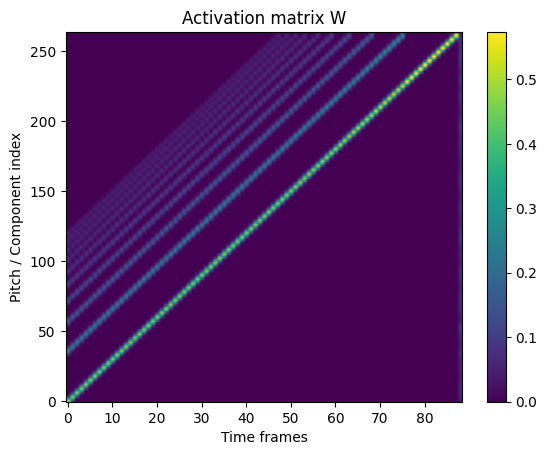

In [428]:
def build_W0(
    sr,
    bins_per_octave,
    n_bins,
    fmin,
    n_harmonics=10,
    decay=1.0,
    sigma=1.5,
    inharmonicity=0.0,
):
    # CQT frequency grid: must match your spectrogram
    freqs = librosa.cqt_frequencies(
        n_bins=n_bins,
        fmin=fmin,
        bins_per_octave=bins_per_octave,
    )

    # Log-frequency coordinates corresponding to CQT bins
    log_freqs = np.log2(freqs)
    k = np.arange(n_bins, dtype=float)

    # Piano pitches: MIDI 21 (A0) through MIDI 108 (C8)
    midi_notes = np.arange(21, 109)

    W0 = np.zeros((n_bins, len(midi_notes)), dtype=float)

    f_max = min(freqs[-1], sr / 2.0)

    for i, m in enumerate(midi_notes):
        f0 = librosa.midi_to_hz(m)
        template = np.zeros(n_bins, dtype=float)

        for h in range(1, n_harmonics + 1):

            # Harmonic frequency, optionally including piano
            # string inharmonicity.
            fh = h * f0 * np.sqrt(
                (1.0 + inharmonicity * h**2)
                / (1.0 + inharmonicity)
            )

            # CRITICAL FIX:
            # Never map out-of-range harmonics onto the
            # first or last CQT bin.
            if fh >= f_max:
                break

            if fh < freqs[0]:
                continue

            # Fractional bin coordinate in log-frequency space
            center = np.interp(
                np.log2(fh),
                log_freqs,
                k,
            )

            # Gaussian harmonic peak
            peak = np.exp(
                -0.5 * ((k - center) / sigma) ** 2
            )

            template += peak / (h ** decay)

        # L2 normalization
        norm = np.linalg.norm(template)
        if norm > 1e-10:
            template /= norm

        W0[:, i] = template

    return W0

def build_noise_basis(n_bins, n_components=2):
    Wn = np.zeros((n_bins, n_components))

    for i in range(n_components):
        # random smooth noise shape
        x = np.random.rand(n_bins)
        x = np.convolve(x, np.hanning(15), mode='same')
        x /= np.linalg.norm(x) + 1e-10
        Wn[:, i] = x

    return Wn
W_0 = build_W0(sr=f_s, bins_per_octave=12*K, n_bins=88 * K, fmin=librosa.note_to_hz('A0'), sigma=1.75)
#W_0 = build_W0(sr=f_s, bins_per_octave=12*K, n_bins=88 * K, fmin=librosa.note_to_hz('A0'), sigma=2.0)
Wn = build_noise_basis(88*K, 1)
W_0 = np.concatenate([W_0, Wn], axis=1)
#W_0 = W_norm(W_0)
#print(W_0.shape)
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(W_0, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [429]:
print(np.sum(W_0[:,40]))

5.852066211129638


In [430]:
print(lind)

[102, 150, 167, 196, 248, 270, 293, 315, 340, 368, 399, 422, 445, 468, 494, 515, 541, 568, 598, 621, 644, 671, 699, 721, 780, 809, 832, 855, 910, 935, 998, 1028, 1052, 1076, 1102, 1127, 1150, 1176, 1206, 1236, 1259, 1283, 1307, 1333, 1354, 1379, 1409, 1435, 1460, 1482, 1504, 1527, 1548, 1577, 1589, 1606, 1631, 1653, 1703, 1758, 1782, 1830, 1853, 1875, 1899, 1926, 1949, 1971, 2001, 2029, 2051, 2073, 2098, 2149, 2172, 2203, 2254, 2298, 2355, 2368, 2385, 2426, 2466, 2493, 2516, 2538, 2559, 2588, 2610, 2626, 2646, 2679, 2702, 2725, 2748, 2773, 2799, 2827, 2856, 2884, 2904, 2926, 2948, 2956, 2973, 2979, 2997, 3016, 3024, 3041, 3065, 3087, 3110, 3132, 3177, 3196, 3201, 3218, 3229, 3249, 3265, 3269, 3272, 3277, 3283, 3288, 3311, 3329, 3348, 3369, 3380, 3397, 3419, 3443, 3467, 3487, 3509, 3531, 3552, 3575, 3595, 3617, 3623, 3631, 3656, 3678, 3704, 3729, 3759, 3784, 3815, 3838, 3860, 3882, 3952, 3968, 3995, 4022, 4045, 4092, 4118, 4145, 4175, 4196, 4214, 4246, 4269, 4294, 4320, 4349, 4375, 4400

In [431]:
# V.shape = (n_frequency_bins, n_frames)
#H_0 = np.random((88,spectrogram.shape[1]))

W, H, history = sparse_nmf(
    spectrogram,
    W_init=W_0,
    n_components=88+1,
    lambda_sparse=1e-3,
    lambda_span=0.5,
    span_indices=lind,
    max_iter=500,
    tol=1e-5,
    random_state=42,
    return_history=True,
)

V_hat = W @ H

print("W:", W.shape)
print("H:", H.shape)
print("Reconstruction:", V_hat.shape)
print("Iterations:", len(history))
print("Final objective:", history[-1]["loss"])

W: (264, 89)
H: (89, 5562)
Reconstruction: (264, 5562)
Iterations: 440
Final objective: -67.61585263159594


In [432]:
print(np.sum(W[:,40]))
print((W[120,40]+W[121,40]+W[122,40])/np.sum(W[:,40]))

3.8132197970569663
0.15842323709066528


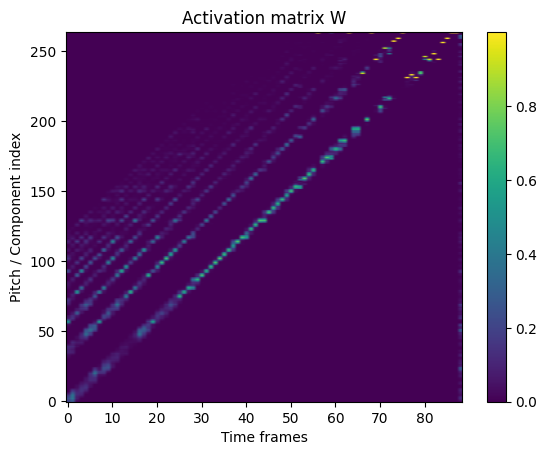

In [433]:
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(W, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [434]:
def reform_W(W_n, t):
  l = []
  for i in range(88):
    s = W_n[i*3,i]+W_n[i*3+1,i]+W_n[i*3+2,i]
    s = s / np.sum(W_n[:,i])
    #print(s)
    if(s>t):
      #for j in range(264):
        #W_c[j,i] = W_n[j,i]
      l.append(i)
  print(l)
  #W_c = W_0[:,l]
  W_c = W_n[:,l]
  return (W_c,l)

In [435]:
(W_n, l) = reform_W(W,0.2)

[19, 25, 26, 27, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 41, 42, 43, 45, 46, 47, 48, 49, 50, 51, 53, 54, 55, 57, 58, 60, 62, 64, 65, 67, 70, 72, 77, 81, 82, 87]


In [436]:
Wa = build_noise_basis(88*K, 1)
W_n = np.concatenate([W_n, Wa], axis=1)
#W_n = np.concatenate([W, Wa], axis=1)
#W_n = W_norm(W_n)

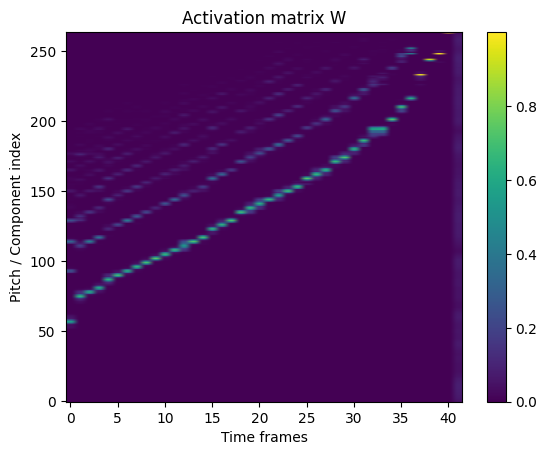

In [437]:
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(W_n, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [438]:
print(W_n.shape[1])

42


In [439]:
# V.shape = (n_frequency_bins, n_frames)
#H_0 = np.random((88,spectrogram.shape[1]))

W, H, history = sparse_nmf(
    spectrogram,
    W_init=W_n,
    n_components=W_n.shape[1],
    lambda_sparse=1e-3,
    lambda_span=0.5,
    span_indices=lind,
    max_iter=500,
    tol=1e-5,
    random_state=42,
    return_history=True,
)

V_hat = W @ H

print("W:", W.shape)
print("H:", H.shape)
print("Reconstruction:", V_hat.shape)
print("Iterations:", len(history))
print("Final objective:", history[-1]["loss"])

W: (264, 42)
H: (42, 5562)
Reconstruction: (264, 5562)
Iterations: 128
Final objective: 124.50505136641044


In [440]:
print(H.shape)

(42, 5562)


In [441]:
#print(H_r.shape)

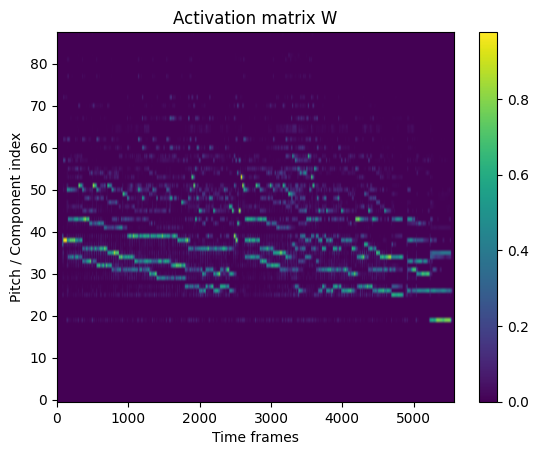

In [442]:
H_r = np.zeros((88,H.shape[1]))
for m in range(len(l)):
  H_r[l[m],:] = H[m,:]
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(H_r, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

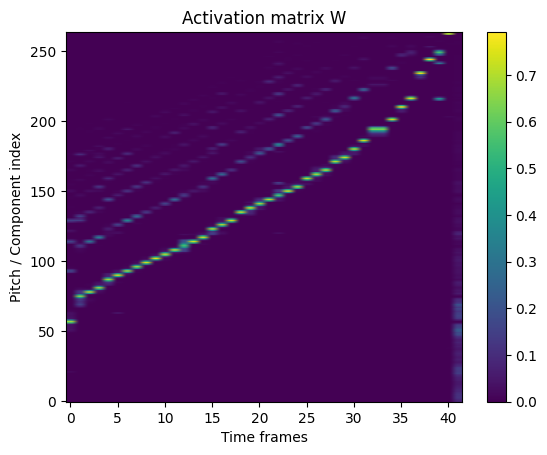

In [443]:
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(W, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

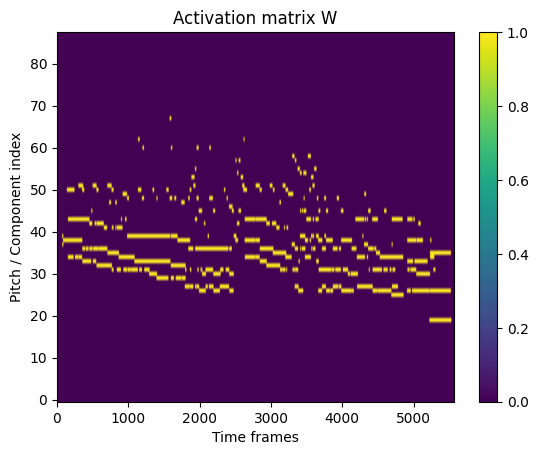

In [444]:
import scipy
from scipy.ndimage import label
def med_filter(X, sz=5):
  X_r = np.zeros(X.shape)
  for i in range(X.shape[0]):
    X_r[i,:] = scipy.ndimage.median_filter(X[i,:], size=sz, cval=0, mode='constant')
  return X_r

def enforce_min_duration(B, min_len=10):
    for q in range(B.shape[0]):
        labels, n = label(B[q])
        for i in range(1, n+1):
            if np.sum(labels == i) < min_len:
                B[q][labels == i] = 0
    return B
H1 = med_filter(H_r)
#H1 = med_filter(H)
H2 = np.zeros_like(H1)
idx = np.argpartition(H1, -10, axis=0)[-10:, :]
H2[idx, np.arange(H1.shape[1])] = H1[idx, np.arange(H1.shape[1])]
H3 = med_filter(H2)
t = H3.max() * 0.2
H4 = (H3 > t).astype(int)
H5 = enforce_min_duration(H4,min_len=15)
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(H5, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [445]:
pip install pretty_midi

In [446]:
import numpy as np
import pretty_midi

def midi_to_binary_matrix(
    midi_input,
    dt=0.02,                     # time quantum in seconds
    pitch_range=(21, 108),  # A0–C8 by default
    min_overlap=0.5         # fraction of frame that must be covered
):
    """
    Convert MIDI to binary (88 x T) note activation matrix using fixed time grid.

    A note is active in a frame if it overlaps the frame
    by at least min_overlap * dt.
    """

    if dt <= 0:
        raise ValueError("dt must be positive (seconds)")

    # Load MIDI
    if isinstance(midi_input, pretty_midi.PrettyMIDI):
        pm = midi_input
    else:
        pm = pretty_midi.PrettyMIDI(midi_input)

    # Time axis
    total_time = pm.get_end_time()
    T = int(np.ceil(total_time / dt))
    frame_times = np.arange(T) * dt

    n_pitches = pitch_range[1] - pitch_range[0] + 1
    B = np.zeros((n_pitches, T), dtype=np.uint8)

    # Process notes
    for instrument in pm.instruments:
        if instrument.is_drum:
            continue

        for note in instrument.notes:
            if not (pitch_range[0] <= note.pitch <= pitch_range[1]):
                continue

            p = note.pitch - pitch_range[0]

            start_frame = int(np.floor(note.start / dt))
            end_frame   = int(np.ceil(note.end   / dt))

            for t in range(start_frame, min(end_frame, T)):
                frame_start = t * dt
                frame_end   = frame_start + dt

                overlap = max(
                    0.0,
                    min(note.end, frame_end) - max(note.start, frame_start)
                )

                if overlap >= min_overlap * dt:
                    B[p, t] = 1

    return B, frame_times

(88, 5513) (88, 5562)


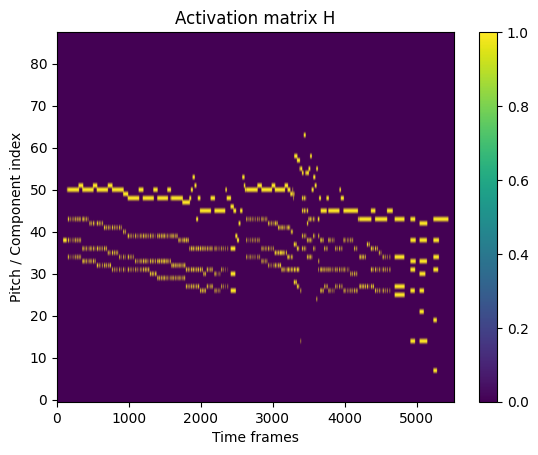

In [447]:
# 20 ms frames (matches typical STFT hop ~512 @ 44.1kHz)
dt = 1024 / f_s
B, times = midi_to_binary_matrix(
    "Prelude-in-E-Minor-Nr-4.mid",
    dt=dt
)
print(B.shape,H4.shape)
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(B, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix H")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [448]:
def evaluate_results(H_et,H):
  #H_et - reference transcription of the piece
  #H - estimated transcription of the piece
  assert H_et.shape == H.shape
  P = 0
  R = 0
  F1 = 0
  TP = 0
  FP = 0
  FN = 0
  for i in range(H_et.shape[1]):
    TP += sum(1 for t, p in zip(H_et[:,i], H[:,i]) if t == 1 and p == 1)
    FP += sum(1 for t, p in zip(H_et[:,i], H[:,i]) if t == 0 and p == 1)
    FN += sum(1 for t, p in zip(H_et[:,i], H[:,i]) if t == 1 and p == 0)
  P = TP / (TP + FP)
  R = TP / (TP + FN)
  F1 = 2 * P * R / (P + R)
  return (P,R,F1)

In [449]:
print(H5.shape)

(88, 5562)


In [450]:
print(evaluate_results(H5[:,:B.shape[1]],B))

(0.6793168880455408, 0.4842200180342651, 0.565411950513293)
